# Proyecto ACD — Parte II: preprocesamiento, features y análisis

**Curso:** Análisis Computacional de Datos (DS3021) · **Docente:** José Espinoza Melgarejo

**Integrantes:**
- Denilson Jermai Cuadros Villegas 202510232
- Enrique Eusebio Torres Chafloque 202510601
- Leo Alexander Torres Ccencho 202410078
- Valeria Bazán Meléndez 202410443
- Lucas Armando Aliaga Mena 201810550

**Repositorio:** [Proyecto-ACD](https://github.com/DnCuadros23/web-scraping-ACD.git)

Este notebook reúne, en un solo archivo y en el orden en que se fue avanzando, el
preprocesamiento del dataset, la construcción de nuevas variables y el análisis de descuentos y
ahorro sobre el catálogo de PlazaVea. El código reutilizable vive en `src/`, que es el mismo que
usa `run_pipeline.py` (raíz del repo), así que el resultado de este notebook y el del pipeline
siempre coinciden.

| | |
|---|---|
| **Entrada** | `data/processed/plazavea_limpio.csv` (dataset inicial, resultado de la Parte I) |
| **Salidas** | `data/interim/plazavea_preprocesado.csv`, `data/final/plazavea_final.csv`, `data/reference/*.csv`, `docs/cifras_oficiales.csv`, `docs/bitacora_decisiones.csv`, `docs/figures/f3_*.png`, `docs/figures/f4_*.png`, `docs/marca_mas_economica.csv` |

## Preparación del entorno

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append("..")  # para poder importar src/ desde notebooks/
from src.preprocessing import (
    unificar_marcas, marcar_outliers_precio, integrar_referencias,
    agrupar_marcas, transformar_precio,
)
from src.features import (
    extraer_contenido_y_precio, clasificar_descuento,
    calcular_oferta_significativa, calcular_segmento_precio, crear_features,
)

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")

DATA = Path("../data")
DOCS = Path("../docs")
FIGURAS = DOCS / "figures"
FIGURAS.mkdir(parents=True, exist_ok=True)
(DATA / "interim").mkdir(parents=True, exist_ok=True)
(DATA / "final").mkdir(parents=True, exist_ok=True)

# --- Bitácora de decisiones: una sola, para todo el notebook ---
bitacora = []
def log(paso, decision, justificacion, alternativa, filas_antes, filas_despues):
    bitacora.append({
        "paso": paso, "decision": decision, "justificacion": justificacion,
        "alternativa_descartada": alternativa,
        "filas_antes": filas_antes, "filas_despues": filas_despues,
        "delta_filas": filas_despues - filas_antes,
    })
    print(f"[{paso}] {decision}")

print("entorno listo")

entorno listo


---

# Preprocesamiento de datos

Dejar el dataset del catálogo de PlazaVea confiable para el análisis: fijar las cifras
oficiales, buscar errores que no se ven a simple vista, marcar (sin borrar) los precios
extremos, integrar tablas de apoyo, reducir la cardinalidad de las marcas y transformar
variables. Cada decisión se registra en la bitácora (sección final de este notebook) con su
justificación y la alternativa descartada.

## 1. Auditoría de partida y cifras oficiales

Se parte del dataset inicial (resultado de la limpieza de la Parte I) y del crudo de la corrida
que usa el equipo. La tabla siguiente fija las cifras que se citan en el informe: **todo número
del informe sale de aquí** (también queda en `../docs/cifras_oficiales.csv`).

In [2]:
df_inicial = pd.read_csv(DATA / "processed" / "plazavea_limpio.csv")
raw = pd.read_csv(sorted((DATA / "raw").glob("plazavea_crudo_*.csv"))[-1])
df = df_inicial.copy()

con_oferta = df[df["tiene_descuento"]]
cifras = {
    "Filas del crudo": len(raw),
    "Filas del dataset inicial (limpio)": len(df_inicial),
    "Columnas del dataset inicial": df_inicial.shape[1],
    "Productos con descuento": int(df["tiene_descuento"].sum()),
    "Productos con descuento (%)": round(df["tiene_descuento"].mean() * 100, 1),
    "Descuentos menores a 10 % (% de los descuentos)": round((con_oferta["descuento_pct"] < 10).mean() * 100, 1),
    "Mediana del ahorro (S/, solo con oferta)": round(con_oferta["ahorro_soles"].median(), 2),
    "Productos con precio Oh!": int(df["tiene_precio_oh"].sum()),
    "Productos con precio Oh! (%)": round(df["tiene_precio_oh"].mean() * 100, 1),
    "Marcas distintas": df["marca"].nunique(),
    "Categorías": df["categoria"].nunique(),
    "Extracción (desde)": df["fecha_extraccion"].min(),
    "Extracción (hasta)": df["fecha_extraccion"].max(),
}
cifras_oficiales = pd.Series(cifras, name="valor").to_frame()
cifras_oficiales.to_csv(DOCS / "cifras_oficiales.csv", encoding="utf-8", lineterminator="\n")
cifras_oficiales

,valor
Filas del crudo,1506
Filas del dataset inicial (limpio),1491
Columnas del dataset inicial,12
Productos con descuento,718
Productos con descuento (%),48.2
Descuentos menores a 10 % (% de los descuentos),34.7
"Mediana del ahorro (S/, solo con oferta)",1.76
Productos con precio Oh!,96
Productos con precio Oh! (%),6.4
Marcas distintas,277


**Lectura.** El dataset inicial tiene 1491 productos (el crudo tenía 1506; la diferencia son
los 15 productos de la categoría Limpieza, excluida en la Parte I por extracción incompleta), 12
columnas y 10 categorías. El 48,2 % de los productos tiene descuento, pero el 34,7 % de esos
descuentos es menor a 10 % y la mediana del ahorro es de solo S/ 1,76: muchas ofertas son
simbólicas. Solo 96 productos (6,4 %) tienen precio con tarjeta Oh!.

## 2. Coherencia de precios

Dos controles directos sobre los precios: que no haya valores imposibles (precios ≤ 0, o regular
menor que venta) y que `descuento_pct`/`ahorro_soles` coincidan con lo que se recalcula desde
`precio_venta` y `precio_regular`.

In [3]:
incoherencias = {
    "precios <= 0": int((df[["precio_venta", "precio_regular"]] <= 0).sum().sum()),
    "precio_regular < precio_venta": int((df["precio_regular"] < df["precio_venta"]).sum()),
    "descuento_pct distinto del recalculado": int(
        (np.abs(df["descuento_pct"] - np.where(df["precio_regular"] > df["precio_venta"],
            (1 - df["precio_venta"] / df["precio_regular"]) * 100, 0.0)) > 0.01).sum()),
    "ahorro_soles distinto del recalculado": int(
        (np.abs(df["ahorro_soles"] - (df["precio_regular"] - df["precio_venta"])) > 0.01).sum()),
}
print(incoherencias)

log("Verificación de precios y coherencia",
    "Sin cambios: no hay precios <= 0 ni regular < venta, y las variables derivadas coinciden con el recálculo",
    "El control queda registrado; se repite en el pipeline para detectar errores de extracción futuros",
    "Recalcular y sobrescribir las columnas (innecesario si ya coinciden)",
    len(df), len(df))

fila_max = df.loc[df["precio_venta"].idxmax()]
print(f"\nprecio más alto: {fila_max['nombre']} (S/ {fila_max['precio_venta']:.2f})")
log("Verificación del precio máximo",
    f"Se conserva '{fila_max['nombre']}' (S/ {fila_max['precio_venta']:.2f}): es un precio real, no un valor de relleno",
    "Verificación manual en la página del producto (23/10/2026): vendido y despachado por Plaza Vea",
    "Tratarlo como valor centinela y convertirlo en nulo",
    len(df), len(df))

{'precios <= 0': 0, 'precio_regular < precio_venta': 0, 'descuento_pct distinto del recalculado': 0, 'ahorro_soles distinto del recalculado': 0}
[Verificación de precios y coherencia] Sin cambios: no hay precios <= 0 ni regular < venta, y las variables derivadas coinciden con el recálculo

precio más alto: Secador Alisador SIEGEN SG-B500 Blanco (S/ 999.00)
[Verificación del precio máximo] Se conserva 'Secador Alisador SIEGEN SG-B500 Blanco' (S/ 999.00): es un precio real, no un valor de relleno


**Resultado.** Las tres variables derivadas coinciden con el recálculo desde los precios:
0 incoherencias. El precio más alto, S/ 999,00 (un secador de cabello), se verificó a mano en la
página del producto: es un precio real, no un valor de relleno, así que se conserva (y queda
marcado como precio extremo en la siguiente sección).

## 3. Marcas escritas de varias formas y la marca "genérico"

No haber celdas vacías no significa que los datos estén bien. Se revisan dos defectos que no se
ven como nulos.

### Marcas escritas de varias formas
Una misma marca escrita de dos formas se contaría como dos marcas y distorsionaría los rankings
y la agrupación. `unificar_marcas` (en `src/preprocessing.py`) detecta estos casos comparando una
clave normalizada (sin tildes, signos ni distinción de mayúsculas) y se queda con la forma más
frecuente.

In [4]:
marcas_antes = df["marca"].nunique()
df = unificar_marcas(df)
marcas_despues = df["marca"].nunique()

print(f"marcas antes: {marcas_antes} | después de unificar: {marcas_despues}")
log("Unificación de marcas",
    f"Se unifican {marcas_antes - marcas_despues} marca(s) con distinta escritura",
    "Una misma marca escrita de dos formas distorsiona el ranking y la agrupación",
    "Unificar también las familias BELL'S (se pierde la distinción entre fresco y envasado)",
    len(df), len(df))

marcas antes: 277 | después de unificar: 276
[Unificación de marcas] Se unifican 1 marca(s) con distinta escritura


**Resultado.** Solo se detecta un caso: `HORNIMAN S` y `HORNIMANS`, que son la misma marca.
Las tres escrituras de la familia BELL'S (`BELL'S`, `BELL'S FRESCOS`, `BELL'S SELECCIÓN`) no son
errores: son líneas distintas que el propio sitio rotula así, y se mantienen separadas.

### La marca "genérico"
El sitio muestra el valor `GENÉRICO` en algunos productos. No es una marca ni un dato faltante:
antes de decidir qué hacer con él, se investigó quién vende esos productos. Se abrieron a mano
los 21 enlaces `GENÉRICO` y una muestra de 25 productos más (10 de Cuidado Personal con mayor
ahorro, 10 aleatorios de Cuidado Personal y 5 de control de otras categorías); la evidencia está
en `../docs/evidencia_vendedor.csv`.

In [5]:
ev = pd.read_csv(DOCS / "evidencia_vendedor.csv").fillna("")
resumen_vendedor = ev.groupby(["grupo", "vendido_por"]).size().unstack(fill_value=0)
display(resumen_vendedor)

def terceros(prefijo):
    sub = ev[ev["grupo"].str.startswith(prefijo)]
    return int((sub["vendido_por"] == "Tercero").sum()), len(sub)

t_gen, n_gen = terceros("GEN")
t_a, n_a = terceros("A.")
t_b, n_b = terceros("B.")
t_c, n_c = terceros("C.")

log("Verificación manual de la marca genérico",
    f"Se conserva: {t_gen} de {n_gen} productos GENÉRICO son de terceros; "
    f"en Cuidado Personal, {t_a} de {n_a} (mayor ahorro) y {t_b} de {n_b} (aleatorios) también lo son; "
    f"control en otras categorías: {t_c} de {n_c}",
    "Es un valor que muestra el sitio, no un dato faltante; cada producto de terceros tiene una marca real "
    "distinta (casi una marca por producto), así que recuperarlas no aporta a la agrupación de marcas",
    "Convertir a nulo, renombrar a SIN MARCA, recuperar la marca a mano o borrar las 21 filas",
    len(df), len(df))

vendido_por,PlazaVea,Tercero
grupo,,
A. Mayores ahorros (Cuidado Personal),1,9
B. Aleatorios de Cuidado Personal,4,6
C. Control: otras categorías,5,0
GENÉRICO (todos los productos),0,21


[Verificación manual de la marca genérico] Se conserva: 21 de 21 productos GENÉRICO son de terceros; en Cuidado Personal, 9 de 10 (mayor ahorro) y 6 de 10 (aleatorios) también lo son; control en otras categorías: 0 de 5


**Decisión.** Los 21 productos `GENÉRICO` son vendidos por terceros (21 de 21), igual que la
mayoría de la muestra de Cuidado Personal (9 de 10 y 6 de 10) y ninguno del control en otras
categorías (0 de 5). Se conserva el valor tal como lo muestra el sitio: no se convierte en nulo
(los `groupby` lo ignorarían sin avisar) ni se borran las filas.

## 4. Outliers de precio: se marcan, no se borran

Los productos caros (suplementos y electrodomésticos en Cuidado Personal, cortes premium en
Carnes y Pescados) son reales: borrarlos eliminaría información. `marcar_outliers_precio` usa la
regla IQR (límites Q1 − 1,5·IQR y Q3 + 1,5·IQR) **dentro de cada categoría**, porque un kilo de
papa y un suplemento no son comparables.

In [6]:
def limites_iqr(serie, k=1.5):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

_, sup_global = limites_iqr(df["precio_venta"])
out_global = (df["precio_venta"] > sup_global).sum()

df = marcar_outliers_precio(df)
out_categoria = int(df["es_outlier_precio"].sum())

print(f"IQR global: límite superior S/ {sup_global:.2f} -> {out_global} productos")
print(f"IQR por categoría: {out_categoria} productos")

log("Marcar outliers de precio",
    f"es_outlier_precio (IQR por categoría, k=1.5): {out_categoria} productos marcados, 0 eliminados",
    "Son productos reales; el IQR por categoría evita que Cuidado Personal marque como atípico lo normal en otras",
    f"Eliminarlos, o usar el IQR global ({out_global} marcados, casi todos de Cuidado Personal)",
    len(df), len(df))

IQR global: límite superior S/ 39.70 -> 159 productos
IQR por categoría: 64 productos
[Marcar outliers de precio] es_outlier_precio (IQR por categoría, k=1.5): 64 productos marcados, 0 eliminados


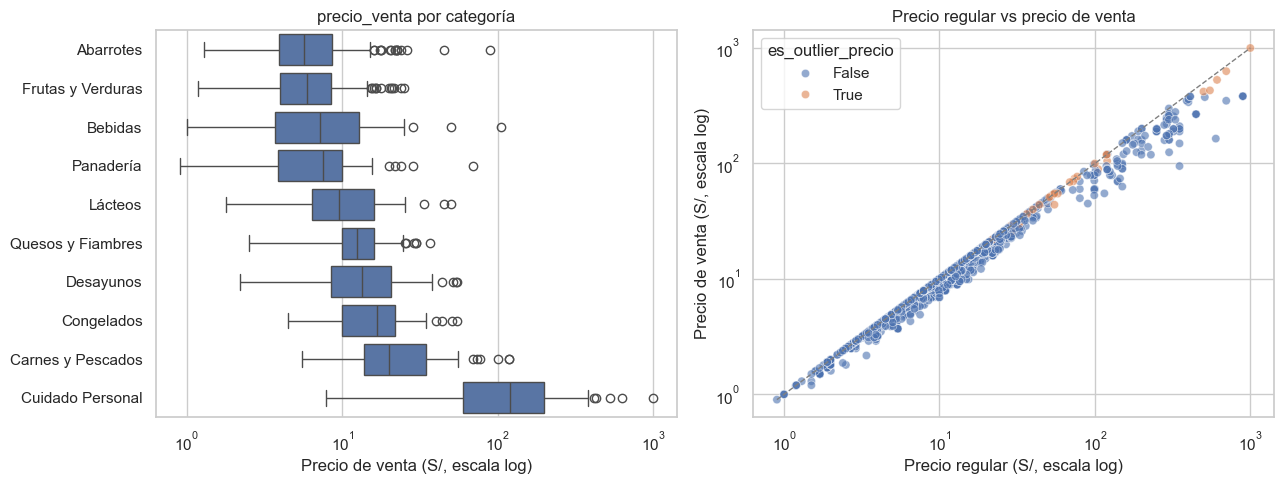

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

orden = df.groupby("categoria")["precio_venta"].median().sort_values().index
sns.boxplot(data=df, y="categoria", x="precio_venta", order=orden, ax=axes[0])
axes[0].set_xscale("log")
axes[0].set_title("precio_venta por categoría")
axes[0].set_xlabel("Precio de venta (S/, escala log)")
axes[0].set_ylabel("")

sns.scatterplot(data=df, x="precio_regular", y="precio_venta", hue="es_outlier_precio", alpha=0.6, ax=axes[1])
lim = [df["precio_regular"].min(), df["precio_regular"].max()]
axes[1].plot(lim, lim, color="gray", linestyle="--", linewidth=1)
axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].set_title("Precio regular vs precio de venta")
axes[1].set_xlabel("Precio regular (S/, escala log)")
axes[1].set_ylabel("Precio de venta (S/, escala log)")

plt.tight_layout()
plt.show()

**Interpretación.** Cuidado Personal tiene la mediana más alta y la mayor dispersión: un
límite global trataría como atípico lo que ahí es normal, por eso el límite se calcula dentro de
cada categoría. En el segundo gráfico, todos los puntos quedan sobre o debajo de la diagonal (el
precio de venta nunca supera al regular); los productos marcados como extremos no tienen más
descuento que el resto — son simplemente productos caros.

## 5. Integración: tablas de apoyo

Hay una sola fuente (una corrida de scraping), así que la integración consiste en unir dos
tablas de referencia con *left join*, verificando que no se pierdan ni dupliquen filas.
`integrar_referencias` hace los dos joins: `dim_categoria.csv` (-> `macro_grupo`) y
`dim_marca.csv` (-> `es_marca_propia`, marcas propias de PlazaVea, validadas a mano contra
[plazavea.com.pe/marcas-propias](https://www.plazavea.com.pe/marcas-propias)).

In [8]:
dim_categoria = pd.read_csv(DATA / "reference" / "dim_categoria.csv")
dim_marca = pd.read_csv(DATA / "reference" / "dim_marca.csv", keep_default_na=False)
dim_marca["es_marca_propia"] = dim_marca["es_marca_propia"].astype(str).str.lower().eq("true")

n0 = len(df)
df = integrar_referencias(df, dim_categoria, dim_marca[["marca", "es_marca_propia"]])

print("productos por macro_grupo:")
print(df["macro_grupo"].value_counts())
print(f"\nmarca propia: {int(df['es_marca_propia'].sum())} productos ({df['es_marca_propia'].mean()*100:.1f} %)")

log("Integración con las tablas de referencia",
    "Left join por categoria -> macro_grupo, y por marca -> es_marca_propia (validate many_to_one)",
    "Permite analizar por grandes familias y comparar marca propia contra marcas nacionales",
    "Inner join (podría perder filas) o inferir la marca propia por el nombre (falsos positivos)",
    n0, len(df))
assert len(df) == n0, "la integración cambió el número de filas"

productos por macro_grupo:
macro_grupo
Frescos             746
Envasados           445
Bebidas             150
Cuidado Personal    150
Name: count, dtype: int64

marca propia: 263 productos (17.6 %)
[Integración con las tablas de referencia] Left join por categoria -> macro_grupo, y por marca -> es_marca_propia (validate many_to_one)


**Resultado.** El *left join* no cambia el número de filas. El 17,6 % de los productos (263)
es de marca propia de PlazaVea. **Limitación:** la página oficial de marcas propias puede cambiar
con el tiempo; por eso se registra la fecha de consulta en `dim_marca.csv`.

## 6. Reducción: `marca_agrupada`

Hay más de 270 marcas y más de 100 aparecen una sola vez: un gráfico por marca sería ilegible.
`agrupar_marcas` conserva las 30 marcas reales más frecuentes, deja `GENÉRICO` como nivel propio
(no es una marca) y agrupa el resto en `OTRAS`. La marca original se conserva.

In [9]:
df = agrupar_marcas(df, top_n=30, sin_marca="GENÉRICO")
print("niveles de marca_agrupada:", df["marca_agrupada"].nunique())
print(df["marca_agrupada"].value_counts().head(5))
print("...")
print("OTRAS:", int((df["marca_agrupada"] == "OTRAS").sum()), "| GENÉRICO:", int((df["marca_agrupada"] == "GENÉRICO").sum()))

log("Reducción de marcas",
    "marca_agrupada = top 30 de marcas reales + GENÉRICO (nivel propio) + OTRAS; marca original se conserva",
    "Reduce la cardinalidad para análisis y gráficos legibles, sin perder la marca original",
    "Top 30 incluyendo GENÉRICO, umbral por frecuencia mínima, o conservar todas las marcas (gráficos ilegibles)",
    len(df), len(df))

niveles de marca_agrupada: 32
marca_agrupada
OTRAS        622
BELL'S       111
PLAZA VEA    106
GLORIA        96
LAIVE         50
Name: count, dtype: int64
...
OTRAS: 622 | GENÉRICO: 21
[Reducción de marcas] marca_agrupada = top 30 de marcas reales + GENÉRICO (nivel propio) + OTRAS; marca original se conserva


## 7. Transformación: `precio_venta_log`

`transformar_precio` aplica `log1p(precio_venta)` para reducir la fuerte asimetría del precio
(pocos productos muy caros dominan la media).

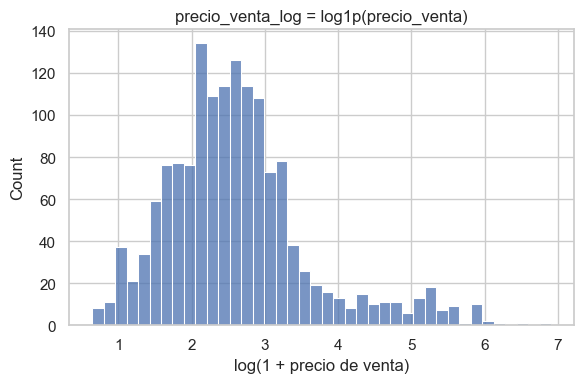

asimetría (skew): 6.60 -> 1.11
[Transformación de precio] precio_venta_log = log1p(precio_venta)


In [10]:
asimetria_antes = df["precio_venta"].skew()
df = transformar_precio(df)
asimetria_despues = df["precio_venta_log"].skew()

fig, ax = plt.subplots(figsize=(6, 4))
sns.histplot(df["precio_venta_log"], bins=40, ax=ax)
ax.set_title("precio_venta_log = log1p(precio_venta)")
ax.set_xlabel("log(1 + precio de venta)")
plt.tight_layout()
plt.show()

print(f"asimetría (skew): {asimetria_antes:.2f} -> {asimetria_despues:.2f}")
log("Transformación de precio",
    "precio_venta_log = log1p(precio_venta)",
    f"log1p reduce la asimetría ({asimetria_antes:.2f} -> {asimetria_despues:.2f}) y es seguro con precios > 0",
    "Min-max o z-score (no cambian la forma de la distribución, solo la escala)",
    len(df), len(df))

## 8. Verificación y exportación

Se comprueban los requisitos de calidad (más de 1000 registros, al menos 6 atributos, nulos ≤
10 % por columna y sin duplicados) y que estén las 5 columnas que esta etapa debe entregar según
el contrato de datos del equipo.

In [11]:
COLUMNAS_PREPROCESAMIENTO = ["es_outlier_precio", "precio_venta_log", "macro_grupo", "es_marca_propia", "marca_agrupada"]
faltan = [c for c in COLUMNAS_PREPROCESAMIENTO if c not in df.columns]

checks = {
    "> 1000 registros": len(df) > 1000,
    ">= 6 atributos": df.shape[1] >= 6,
    "<= 10 % de nulos por columna": df.isna().mean().max() * 100 <= 10,
    "sin duplicados por url_producto": not df["url_producto"].duplicated().any(),
    "columnas del contrato presentes": not faltan,
    "mismas filas que el dataset inicial": len(df) == len(df_inicial),
}
for nombre, ok in checks.items():
    print(("OK   " if ok else "FALLA"), nombre)
assert all(checks.values()), f"fallan requisitos: {[k for k, v in checks.items() if not v]}"

ruta_preprocesado = DATA / "interim" / "plazavea_preprocesado.csv"
df.to_csv(ruta_preprocesado, index=False, encoding="utf-8", lineterminator="\n")
print(f"\nexportado: {ruta_preprocesado} ({df.shape[0]} filas, {df.shape[1]} columnas)")

OK    > 1000 registros
OK    >= 6 atributos
OK    <= 10 % de nulos por columna
OK    sin duplicados por url_producto
OK    columnas del contrato presentes
OK    mismas filas que el dataset inicial

exportado: ..\data\interim\plazavea_preprocesado.csv (1491 filas, 17 columnas)


**En resumen.** El dataset inicial no tiene nulos ni duplicados, pero sí defectos
escondidos: una marca escrita de dos formas y 21 productos `GENÉRICO`, todos vendidos por
terceros. El 4,3 % de los productos (64) tiene un precio extremo dentro de su categoría; ninguno
se elimina, porque son productos reales. El 17,6 % de los productos (263) es de marca propia de
PlazaVea. Todo se conserva y se marca; no se borra ninguna fila (1491 antes y después).

---

# Ingeniería de características

Construir las variables que permiten comparar productos de forma justa y responder los
objetivos de análisis, partiendo del dataset preprocesado de la sección anterior (sigue en
memoria como `df`, con sus 1491 filas y las 5 columnas ya agregadas).

## 1. Contenido y precio unitario

`extraer_contenido_y_precio` (en `src/features.py`) saca el contenido del producto (peso,
volumen o unidades) del nombre con expresiones regulares y calcula el precio por 100 g, 100 ml o
por unidad — la métrica que de verdad permite comparar productos de distinto tamaño.

In [12]:
df[["cantidad_base", "tipo_unidad_medida", "precio_unitario_normalizado"]] = df.apply(
    extraer_contenido_y_precio, axis=1
)

tasa_parseo = (1 - df["cantidad_base"].isna().mean()) * 100
print(f"filas con contenido reconocido: {tasa_parseo:.1f} %")
print(df["tipo_unidad_medida"].value_counts())
df[["nombre", "precio_venta", "tipo_unidad_medida", "precio_unitario_normalizado"]].head(5)

filas con contenido reconocido: 57.7 %
tipo_unidad_medida
desconocido    630
100g           569
100ml          160
unidad         132
Name: count, dtype: int64


,nombre,precio_venta,tipo_unidad_medida,precio_unitario_normalizado
0,Galletas OREO Original Paquete 6un,4.7,unidad,0.7833
1,Minis Bombones de Chocolate BON O BON Multipac...,26.0,desconocido,NaN
2,Galleta CHOCOBUM Empaque 33g Paquete 6un,4.2,100g,12.7273
3,Galletas OREO Original Paquete 12un,8.4,unidad,0.7000
4,Gomas AMBROSOLI Cerebros Bolsa 250g,14.5,100g,5.8000


**Limitación.** El regex reconoce el contenido en el 57,7 % de los nombres; el resto queda
como `desconocido` (productos a granel, combos o presentaciones sin peso/volumen explícito en el
nombre, por ejemplo "Palta Fuerte x Kg" sin el número, o paquetes promocionales). Queda anotado
aquí como limitación conocida en vez de completarlo a mano (rompería la reproducibilidad).

## 2. Clasificación del descuento

`clasificar_descuento` agrupa `descuento_pct` en cuatro rangos, para comparar categorías enteras
en vez de un porcentaje exacto por producto.

In [13]:
df["rango_descuento"] = df["descuento_pct"].apply(clasificar_descuento)
print(df["rango_descuento"].value_counts())

rango_descuento
Sin descuento         773
Moderado (10%-25%)    366
Bajo (<10%)           249
Alto (>25%)           103
Name: count, dtype: int64


## 3. Precio unitario por categoría (un ejemplo de uso)

Una primera mirada a para qué sirve `precio_unitario_normalizado`: compara el precio por 100 g /
100 ml / unidad entre categorías, algo que `precio_venta` por sí solo no permite (un kilo de
arroz y una lata de atún no se comparan por su precio total).

In [14]:
resumen_unitario = (
    df.dropna(subset=["precio_unitario_normalizado"])
    .groupby(["categoria", "tipo_unidad_medida"])["precio_unitario_normalizado"]
    .agg(["count", "mean", "median"]).round(2)
)
resumen_unitario.head(10)

count  mean  median
categoria         tipo_unidad_medida                     
Abarrotes         100g                   90  5.49    2.54
                  100ml                   8  0.75    0.79
                  unidad                 23  1.03    0.87
Bebidas           100g                    3  7.79    7.69
                  100ml                 103  1.34    0.50
                  unidad                  2  8.38    8.38
Carnes y Pescados 100g                   35  3.38    1.99
Congelados        100g                   27  5.05    4.02
                  100ml                  15  1.89    1.75
                  unidad                 42  2.63    1.08

## 4. Dos variables que faltaban: oferta significativa y segmento de precio

El contrato de datos del equipo (acordado el 21 de octubre) definía también `oferta_significativa`
y `segmento_precio`, que el análisis de descuentos y ahorro (más adelante en este notebook)
necesita. Se agregan aquí, con `crear_features` (que ya incluye los pasos de arriba más estas
dos), para que el dataset final quede completo desde esta sección.

In [15]:
n0 = len(df)
df = crear_features(df)  # repite los pasos 1-2 (son idempotentes) y agrega oferta_significativa + segmento_precio
assert len(df) == n0, "crear_features cambió el número de filas"

print("oferta_significativa:")
print(df["oferta_significativa"].value_counts())
print("\nsegmento_precio:")
print(df["segmento_precio"].value_counts())

log("Contenido, precio unitario y rango de descuento",
    "cantidad_base/tipo_unidad_medida/precio_unitario_normalizado por regex sobre el nombre; rango_descuento por umbrales",
    "Permite comparar precios de forma justa entre presentaciones distintas",
    "Pedir el peso/volumen a mano para el 42,3 % sin match (rompería la reproducibilidad)",
    n0, len(df))
log("Oferta significativa y segmento de precio",
    "Se agregan aquí (estaban en el contrato de datos pero no se habían calculado todavía)",
    "El análisis de descuentos y ahorro las necesita: umbral de oferta real y terciles de precio por categoría",
    "Dejarlas pendientes para que se recalcularan más adelante (duplicaría la lógica)",
    n0, len(df))

oferta_significativa:
oferta_significativa
False    1165
True      326
Name: count, dtype: int64

segmento_precio:
segmento_precio
Económico    505
Medio        494
Premium      492
Name: count, dtype: int64
[Contenido, precio unitario y rango de descuento] cantidad_base/tipo_unidad_medida/precio_unitario_normalizado por regex sobre el nombre; rango_descuento por umbrales
[Oferta significativa y segmento de precio] Se agregan aquí (estaban en el contrato de datos pero no se habían calculado todavía)


## 5. Dataset final y verificación

Se verifican los mismos cuatro requisitos de calidad de la sección anterior (aplicados a las
columnas que deben quedar completas; `cantidad_base` y `precio_unitario_normalizado` se reportan
aparte, por la limitación de la sección 1) y se exporta el dataset final.

In [16]:
COLUMNAS_SIN_NULOS_ESPERADOS = ["cantidad_base", "tipo_unidad_medida", "precio_unitario_normalizado"]
columnas_estrictas = [c for c in df.columns if c not in COLUMNAS_SIN_NULOS_ESPERADOS]

checks = {
    "> 1000 registros": len(df) > 1000,
    ">= 6 atributos": df.shape[1] >= 6,
    "<= 10 % de nulos por columna (salvo cantidad_base/precio_unitario_normalizado)":
        df[columnas_estrictas].isna().mean().max() * 100 <= 10,
    "sin duplicados por url_producto": not df["url_producto"].duplicated().any(),
}
for nombre, ok in checks.items():
    print(("OK   " if ok else "FALLA"), nombre)
assert all(checks.values()), f"fallan requisitos: {[k for k, v in checks.items() if not v]}"

ruta_final = DATA / "final" / "plazavea_final.csv"
df.to_csv(ruta_final, index=False, encoding="utf-8", lineterminator="\n")
print(f"\nexportado: {ruta_final} ({df.shape[0]} filas, {df.shape[1]} columnas)")

OK    > 1000 registros
OK    >= 6 atributos
OK    <= 10 % de nulos por columna (salvo cantidad_base/precio_unitario_normalizado)
OK    sin duplicados por url_producto

exportado: ..\data\final\plazavea_final.csv (1491 filas, 23 columnas)


**En resumen.** `precio_unitario_normalizado` permite comparar productos de distinto
tamaño de forma justa; se reconoce en el 57,7 % de los nombres (limitación: productos a granel o
sin medida explícita). `rango_descuento`, `oferta_significativa` y `segmento_precio` quedan
listas para el análisis siguiente sin tener que recalcularlas. El dataset final tiene 1491 filas
y 23 columnas, y queda en `../data/final/plazavea_final.csv`.

---

# Análisis de descuentos y ahorro

Responder dónde hay más ofertas en el catálogo y cuánto ahorra de verdad el cliente cuando las
hay, sobre el dataset final de la sección anterior (sigue en memoria como `df`, con sus 23
columnas). También queda el pipeline ejecutable con un solo comando (`run_pipeline.py`, raíz del
repo, usa las mismas funciones de `src/`) y las figuras que alimentan la presentación.

## 1. Panorama general

Estadísticos descriptivos de precio, descuento y ahorro, y su distribución. El precio se mira en
escala logarítmica porque unos pocos productos caros (sobre todo en Cuidado Personal) dominan la
media.

In [17]:
con_oferta = df[df["tiene_descuento"]]

panorama = pd.DataFrame({
    "precio_venta (todos)": df["precio_venta"].agg(["mean", "median", "std", "skew"]),
    "descuento_pct (con oferta)": con_oferta["descuento_pct"].agg(["mean", "median", "std", "skew"]),
    "ahorro_soles (con oferta)": con_oferta["ahorro_soles"].agg(["mean", "median", "std", "skew"]),
}).round(2)
panorama

,precio_venta (todos),descuento_pct (con oferta),ahorro_soles (con oferta)
mean,26.68,15.38,14.35
median,11.00,13.02,1.76
std,60.07,11.14,48.18
skew,6.60,1.53,6.90


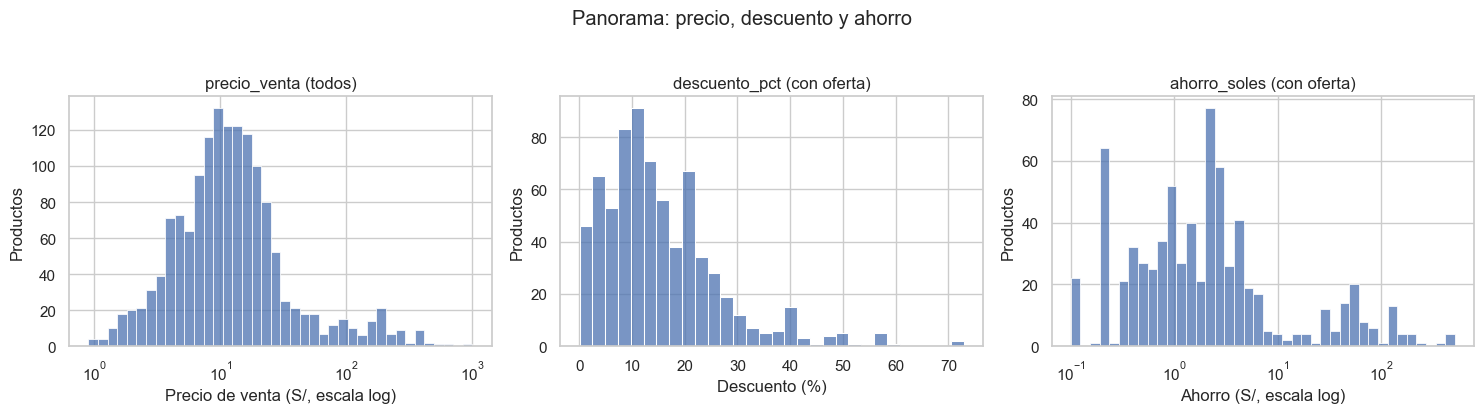

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(df["precio_venta"], bins=40, ax=axes[0], log_scale=(True, False))
axes[0].set_title("precio_venta (todos)")
axes[0].set_xlabel("Precio de venta (S/, escala log)")

sns.histplot(con_oferta["descuento_pct"], bins=30, ax=axes[1])
axes[1].set_title("descuento_pct (con oferta)")
axes[1].set_xlabel("Descuento (%)")

sns.histplot(con_oferta["ahorro_soles"], bins=40, ax=axes[2], log_scale=(True, False))
axes[2].set_title("ahorro_soles (con oferta)")
axes[2].set_xlabel("Ahorro (S/, escala log)")

for ax in axes:
    ax.set_ylabel("Productos")

fig.suptitle("Panorama: precio, descuento y ahorro", y=1.03)
plt.tight_layout()
plt.savefig(FIGURAS / "f3_panorama.png", dpi=120, bbox_inches="tight")
plt.show()

**Interpretación.** El precio de venta es muy asimétrico (la mediana, S/ 11,00, es menos de
la mitad de la media, S/ 26,68): pocos productos caros estiran la cola. El descuento, cuando
existe, se concentra entre 5 % y 20 % (mediana 13,0 %). El ahorro en soles es el más asimétrico
de los tres (mediana S/ 1,75 frente a una media de S/ 14,35): la mayoría de las ofertas son
pequeñas en soles, y un grupo chico de productos caros (sección 4) eleva la media.

## 2. ¿Dónde hay más ofertas?

Tasa de descuento (% de productos con oferta activa) por categoría y por macro_grupo, con el
tamaño de cada grupo indicado.

In [19]:
tasa_categoria = (
    df.groupby("categoria")
    .agg(n=("tiene_descuento", "size"), tasa_pct=("tiene_descuento", lambda s: round(s.mean() * 100, 1)))
    .sort_values("tasa_pct", ascending=False)
)
tasa_macro = (
    df.groupby("macro_grupo")
    .agg(n=("tiene_descuento", "size"), tasa_pct=("tiene_descuento", lambda s: round(s.mean() * 100, 1)))
    .sort_values("tasa_pct", ascending=False)
)
print(tasa_categoria)
print()
print(tasa_macro)

                     n  tasa_pct
categoria                       
Cuidado Personal   150      80.0
Desayunos          150      63.3
Quesos y Fiambres  149      57.7
Abarrotes          150      56.7
Lácteos            150      56.7
Bebidas            150      49.3
Panadería          147      38.8
Congelados         145      38.6
Carnes y Pescados  150      28.0
Frutas y Verduras  150      12.0

                    n  tasa_pct
macro_grupo                    
Cuidado Personal  150      80.0
Envasados         445      53.0
Bebidas           150      49.3
Frescos           746      38.6


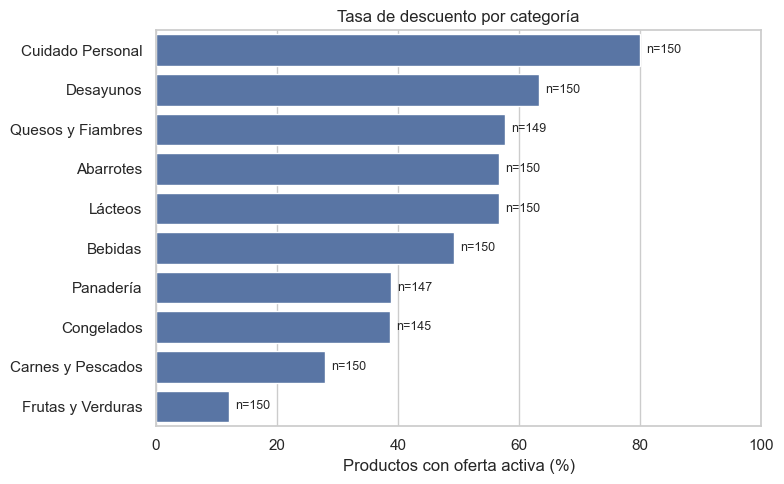

In [20]:
fig, ax = plt.subplots(figsize=(8, 5))
orden = tasa_categoria.index
sns.barplot(x=tasa_categoria["tasa_pct"], y=orden, order=orden, ax=ax, color="#4C72B0")
for i, (cat, fila) in enumerate(tasa_categoria.iterrows()):
    ax.text(fila["tasa_pct"] + 1, i, f"n={int(fila['n'])}", va="center", fontsize=9)
ax.set_title("Tasa de descuento por categoría")
ax.set_xlabel("Productos con oferta activa (%)")
ax.set_ylabel("")
ax.set_xlim(0, 100)
plt.tight_layout()
plt.savefig(FIGURAS / "f3_tasa_descuento_categoria.png", dpi=120, bbox_inches="tight")
plt.show()

**Interpretación.** Cuidado Personal tiene la tasa de descuento más alta con diferencia
(80,0 % de sus 150 productos), y Frutas y Verduras la más baja (12,0 %): la misma brecha de 68
puntos porcentuales que ya se había visto en la Parte I se confirma con el dataset final. Por
macro_grupo, Cuidado Personal (80,0 %) está muy por delante de Envasados (53,0 %), Bebidas
(49,3 %) y Frescos (38,6 %) — el macro_grupo Frescos queda más bajo porque mezcla Frutas y
Verduras con categorías de mayor descuento como Lácteos.

**Limitación.** Es una foto de un solo día y de una sola zona de entrega: no dice si una
categoría tiene más ofertas *en general*, solo que las tuvo ese día.

## 3. ¿Cuánto se ahorra de verdad?

`rango_descuento` agrupa el tamaño del descuento; `oferta_significativa` (umbral del contrato:
descuento ≥ 10 % y ahorro ≥ S/ 2) separa las ofertas que de verdad mueven el bolsillo de las
simbólicas.

In [21]:
print("rango_descuento (todo el dataset):")
dist_rango = df["rango_descuento"].value_counts()
print(pd.concat([dist_rango, (dist_rango / len(df) * 100).round(1).rename("pct")], axis=1))

print("\noferta_significativa por categoría (%):")
tabla_os = (df.groupby("categoria")["oferta_significativa"].mean() * 100).round(1).sort_values(ascending=False)
print(tabla_os)

corr = con_oferta[["descuento_pct", "ahorro_soles"]].corr().iloc[0, 1]
print(f"\ncorrelación descuento_pct vs ahorro_soles (con oferta): {corr:.2f}")

rango_descuento (todo el dataset):
                    count   pct
rango_descuento                
Sin descuento         773  51.8
Moderado (10%-25%)    366  24.5
Bajo (<10%)           249  16.7
Alto (>25%)           103   6.9

oferta_significativa por categoría (%):
categoria
Cuidado Personal     74.0
Desayunos            33.3
Congelados           32.4
Quesos y Fiambres    24.2
Abarrotes            16.0
Lácteos              14.0
Carnes y Pescados    13.3
Panadería             6.1
Bebidas               2.7
Frutas y Verduras     2.7
Name: oferta_significativa, dtype: float64

correlación descuento_pct vs ahorro_soles (con oferta): 0.64


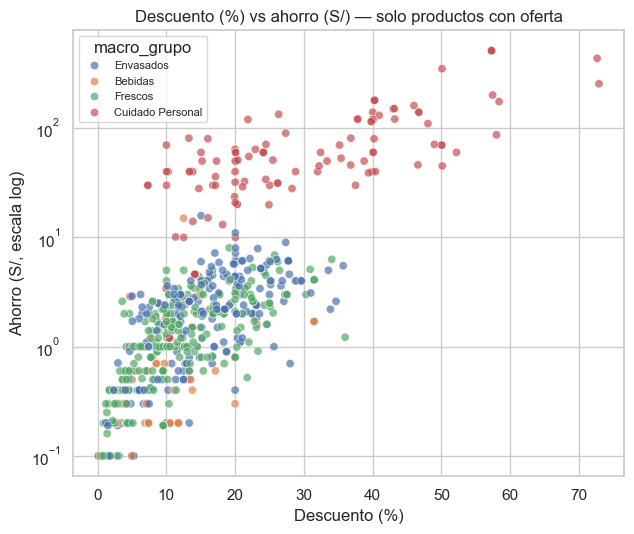

In [22]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
sns.scatterplot(data=con_oferta, x="descuento_pct", y="ahorro_soles", hue="macro_grupo", alpha=0.7, ax=ax)
ax.set_yscale("log")
ax.set_title("Descuento (%) vs ahorro (S/) — solo productos con oferta")
ax.set_xlabel("Descuento (%)")
ax.set_ylabel("Ahorro (S/, escala log)")
ax.legend(title="macro_grupo", fontsize=8)
plt.tight_layout()
plt.savefig(FIGURAS / "f3_dispersion_descuento_ahorro.png", dpi=120, bbox_inches="tight")
plt.show()

**Interpretación.** El 51,8 % del catálogo no tiene oferta; del resto, los descuentos
"Moderado (10%-25%)" son los más comunes (24,5 % del total) y "Alto (>25%)" los menos (6,9 %). La
correlación entre descuento_pct y ahorro_soles es de 0,64: positiva pero lejos de perfecta,
porque el ahorro en soles también depende del precio del producto. `oferta_significativa` resume
esto: solo el 21,9 % del catálogo (326 de 1491) tiene una oferta que cumple ambos umbrales a la
vez, y Cuidado Personal vuelve a liderar (74,0 %), muy por delante de Desayunos (33,3 %) y
Congelados (32,4 %).

**Limitación.** Los umbrales (≥10 % y ≥S/ 2) son los que acordó el equipo; con otro umbral la
proporción de "oferta significativa" cambia.

## 4. La anomalía de Cuidado Personal

La sección anterior ya muestra que Cuidado Personal concentra las ofertas más grandes. Aquí se
mira de cerca qué productos son.

In [23]:
ahorro_categoria = df.groupby("categoria")["ahorro_soles"].agg(["mean", "median"]).round(2).sort_values("mean", ascending=False)
print(ahorro_categoria)

top10 = df.nlargest(10, "ahorro_soles")[["nombre", "categoria", "precio_regular", "precio_venta", "ahorro_soles", "descuento_pct"]]
top10

                    mean  median
categoria                       
Cuidado Personal   61.35   39.96
Desayunos           1.82    0.50
Congelados          1.14    0.00
Quesos y Fiambres   1.10    0.50
Abarrotes           0.88    0.25
Lácteos             0.77    0.19
Carnes y Pescados   0.68    0.00
Bebidas             0.47    0.00
Panadería           0.39    0.00
Frutas y Verduras   0.13    0.00


,nombre,categoria,precio_regular,precio_venta,ahorro_soles,descuento_pct
522,Zeaxan 6 Pack Cuidado para Tu Salud Ocular,Cuidado Personal,894.0,382.0,512.0,57.27
598,CALMANO - 6 pack - CAPSULAS para VARICES y HEM...,Cuidado Personal,894.0,382.0,512.0,57.27
599,CALMANO capsulas pack x 3 + CALMANO crema pack...,Cuidado Personal,894.0,382.0,512.0,57.27
597,MUTANT MASS DE 5LB VAINILLA - GANADOR MASA,Cuidado Personal,599.0,164.0,435.0,72.62
451,Secadora de Cabello SIEGEN SG-B3160 Blanco,Cuidado Personal,699.0,349.0,350.0,50.07
575,PROTEÍNA WHEY PRO 1.1 KG COOKIES + CREATINA UN...,Cuidado Personal,350.0,94.9,255.1,72.89
568,PROTEÍNA WHEY PRO 5 KG CHOCOLATE y muñequera,Cuidado Personal,350.0,149.0,201.0,57.43
466,HAIREX para Caida de Cabello 3 Pack,Cuidado Personal,447.0,267.0,180.0,40.27
517,Glyconorm 3 Pack Alivia y Controla Síntomas de...,Cuidado Personal,447.0,267.0,180.0,40.27
524,Flexacil Ultra 3 Pack para Molestias Articular...,Cuidado Personal,447.0,267.0,180.0,40.27


**Interpretación.** El ahorro promedio en Cuidado Personal es S/ 61,35, frente a S/ 1,82 en
la siguiente categoría (Desayunos) y S/ 0,82 en el resto del catálogo junto. Dentro de la propia
categoría, la mediana (S/ 39,96) es bastante menor que la media: unos pocos productos muy caros
(suplementos, proteínas en polvo y una secadora de cabello, todos sobre S/ 180 de ahorro) estiran
el promedio. Los 10 mayores ahorros del catálogo entero son, sin excepción, de Cuidado Personal —
coherente con que esa categoría ya tenía la mediana de precio más alta (sección de outliers de
precio).

**Limitación.** Son 150 productos por categoría sin muestreo aleatorio; no se puede afirmar que
esta brecha se mantenga en todo el catálogo real de PlazaVea.

## 5. ¿Los productos premium se rebajan más o menos?

`segmento_precio` divide cada categoría en terciles de precio_venta. Se cruza con `macro_grupo`
y la tasa de descuento para ver si el patrón es el mismo en todas partes.

segmento_precio   Económico  Medio  Premium
macro_grupo                                
Bebidas                62.7   40.8     44.0
Cuidado Personal       67.3   83.3     90.0
Envasados              54.7   49.3     55.0
Frescos                37.3   43.8     34.6


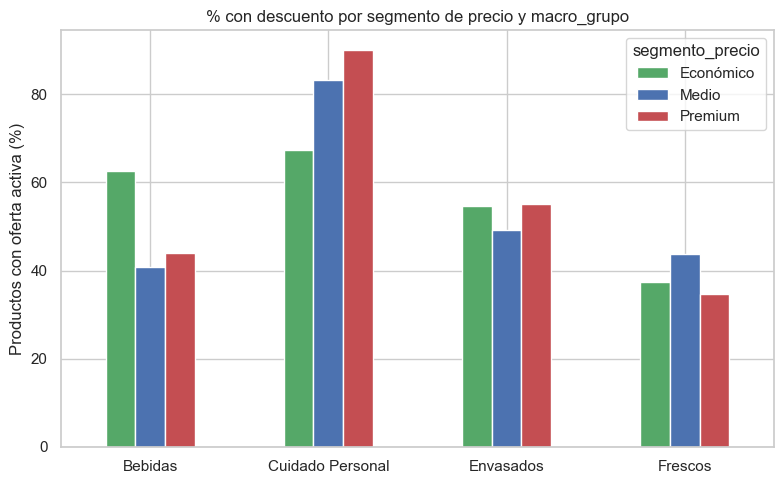

In [24]:
seg = (
    df.groupby(["macro_grupo", "segmento_precio"], observed=True)["tiene_descuento"]
    .mean().mul(100).round(1).unstack()
)
print(seg)

fig, ax = plt.subplots(figsize=(8, 5))
seg.plot(kind="bar", ax=ax, color=["#55A868", "#4C72B0", "#C44E52"])
ax.set_title("% con descuento por segmento de precio y macro_grupo")
ax.set_xlabel("")
ax.set_ylabel("Productos con oferta activa (%)")
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.legend(title="segmento_precio")
plt.tight_layout()
plt.savefig(FIGURAS / "f3_segmentacion_precio.png", dpi=120, bbox_inches="tight")
plt.show()

**Interpretación.** No hay un patrón único: depende del macro_grupo. En Cuidado Personal
los productos Premium se rebajan claramente más (90,0 % vs 67,3 % en Económico); en Bebidas pasa
lo contrario (Económico 62,7 % vs Premium 44,0 %); en Frescos y Envasados la diferencia entre
segmentos es chica y sin una dirección clara. En conjunto, el precio del producto por sí solo no
predice si tiene oferta (48,1 % Económico vs 47,4 % Premium): lo que sí importa es a qué
macro_grupo pertenece (sección 2).

## 6. El pipeline en código

`run_pipeline.py` (raíz del repo) encadena las mismas funciones de `src/` que usa este notebook
— limpieza, preprocesamiento e ingeniería de características — para regenerar el dataset final y
una base SQLite (`data/plazavea.db`) con un solo comando:

```bash
python run_pipeline.py            # usa el crudo ya guardado en data/raw/
python run_pipeline.py --scrape   # antes, vuelve a extraer el catálogo (tarda horas)
```

La extracción web (`src/ingestion.py`, el scraper de la Parte I) queda como opción `--scrape`
porque tarda horas; no se vuelve a ejecutar en este notebook.

## 7. Bitácora de decisiones y verificación final

In [25]:
df_bitacora = pd.DataFrame(bitacora)
ruta_bitacora = DOCS / "bitacora_decisiones.csv"
df_bitacora.to_csv(ruta_bitacora, index=False, encoding="utf-8", lineterminator="\n")
print(f"bitácora exportada: {len(df_bitacora)} decisiones -> {ruta_bitacora}")
df_bitacora

bitácora exportada: 10 decisiones -> ..\docs\bitacora_decisiones.csv


,paso,decision,justificacion,alternativa_descartada,filas_antes,filas_despues,delta_filas
0,Verificación de precios y coherencia,Sin cambios: no hay precios <= 0 ni regular < ...,El control queda registrado; se repite en el p...,Recalcular y sobrescribir las columnas (innece...,1491,1491,0
1,Verificación del precio máximo,Se conserva 'Secador Alisador SIEGEN SG-B500 B...,Verificación manual en la página del producto ...,Tratarlo como valor centinela y convertirlo en...,1491,1491,0
2,Unificación de marcas,Se unifican 1 marca(s) con distinta escritura,Una misma marca escrita de dos formas distorsi...,Unificar también las familias BELL'S (se pierd...,1491,1491,0
3,Verificación manual de la marca genérico,Se conserva: 21 de 21 productos GENÉRICO son d...,"Es un valor que muestra el sitio, no un dato f...","Convertir a nulo, renombrar a SIN MARCA, recup...",1491,1491,0
4,Marcar outliers de precio,"es_outlier_precio (IQR por categoría, k=1.5): ...",Son productos reales; el IQR por categoría evi...,"Eliminarlos, o usar el IQR global (159 marcado...",1491,1491,0
5,Integración con las tablas de referencia,"Left join por categoria -> macro_grupo, y por ...",Permite analizar por grandes familias y compar...,Inner join (podría perder filas) o inferir la ...,1491,1491,0
6,Reducción de marcas,marca_agrupada = top 30 de marcas reales + GEN...,Reduce la cardinalidad para análisis y gráfico...,"Top 30 incluyendo GENÉRICO, umbral por frecuen...",1491,1491,0
7,Transformación de precio,precio_venta_log = log1p(precio_venta),log1p reduce la asimetría (6.60 -> 1.11) y es ...,Min-max o z-score (no cambian la forma de la d...,1491,1491,0
8,"Contenido, precio unitario y rango de descuento",cantidad_base/tipo_unidad_medida/precio_unitar...,Permite comparar precios de forma justa entre ...,"Pedir el peso/volumen a mano para el 42,3 % si...",1491,1491,0
9,Oferta significativa y segmento de precio,Se agregan aquí (estaban en el contrato de dat...,El análisis de descuentos y ahorro las necesit...,Dejarlas pendientes para que se recalcularan m...,1491,1491,0


In [26]:
figuras_esperadas = ["f3_panorama.png", "f3_tasa_descuento_categoria.png",
                     "f3_dispersion_descuento_ahorro.png", "f3_segmentacion_precio.png"]
for nombre in figuras_esperadas:
    ruta = FIGURAS / nombre
    print(("OK   " if ruta.exists() else "FALLA"), ruta)

print("\ndataset final:", df.shape, "| columnas:", list(df.columns))

OK    ..\docs\figures\f3_panorama.png
OK    ..\docs\figures\f3_tasa_descuento_categoria.png
OK    ..\docs\figures\f3_dispersion_descuento_ahorro.png
OK    ..\docs\figures\f3_segmentacion_precio.png

dataset final: (1491, 23) | columnas: ['id_producto', 'nombre', 'marca', 'categoria', 'precio_venta', 'precio_regular', 'tiene_precio_oh', 'descuento_pct', 'url_producto', 'fecha_extraccion', 'tiene_descuento', 'ahorro_soles', 'es_outlier_precio', 'macro_grupo', 'es_marca_propia', 'marca_agrupada', 'precio_venta_log', 'cantidad_base', 'tipo_unidad_medida', 'precio_unitario_normalizado', 'rango_descuento', 'oferta_significativa', 'segmento_precio']


## 8. Insumos para las conclusiones

- **Dónde hay más ofertas.** Cuidado Personal concentra la mayor tasa de descuento (80,0 % de
  150 productos) y Frutas y Verduras la menor (12,0 %). *Limitación:* una sola fecha y zona de
  entrega, sin muestreo aleatorio.
- **Cuánto se ahorra de verdad.** El 48,2 % del catálogo tiene oferta, pero solo el 21,9 % es
  una oferta significativa (≥10 % y ≥S/ 2); la mediana de ahorro real es de solo S/ 1,75, salvo
  en Cuidado Personal (mediana S/ 39,96). *Limitación:* los umbrales de "significativa" son una
  definición del equipo, no un estándar externo.

## 9. Conclusiones

**Qué se encontró**
- La tasa de descuento varía mucho por categoría (80,0 % en Cuidado Personal, 12,0 % en Frutas y
  Verduras) y ese orden se mantiene al mirarlo por macro_grupo.
- El ahorro real suele ser chico: la mitad de las ofertas del catálogo ahorran S/ 1,75 o menos.
  Cuidado Personal es la excepción clara, con ofertas de hasta S/ 512 en productos de alto precio.
- Solo 1 de cada 5 productos del catálogo tiene una oferta "significativa" a la vez en porcentaje
  y en soles.
- Que un producto sea Económico, Medio o Premium dentro de su categoría no predice por sí solo si
  tiene descuento: el patrón depende del macro_grupo.

**Para seguir trabajando**
- `src/ingestion.py`, `src/preprocessing.py` y `src/features.py` ya existen y `run_pipeline.py`
  regenera el dataset final y la base SQLite con un solo comando — útil para la sección del
  informe sobre el diseño del pipeline y para reproducir el proyecto desde cero.
- Las 4 figuras de esta parte están en `docs/figures/f3_*.png`, listas para las diapositivas
  (contenido en `docs/diapositivas_p3.md`) y para la sección de análisis del informe.
- El dataset final (`data/final/plazavea_final.csv`, 1491 filas × 23 columnas) ya incluye todas
  las columnas del preprocesamiento y de la ingeniería de características.

---

# Comparación de precios entre marcas y tarjeta Oh!

Responde los dos objetivos que faltaban del informe de la Parte I, partiendo del dataset final
de la sección anterior (sigue en memoria como `df`, 1491 filas × 23 columnas):

- **Objetivo 5.** Comparar precios entre marcas de productos similares, para identificar las
  alternativas más económicas.
- **Objetivo 6.** Determinar en qué categorías se concentra el precio exclusivo con tarjeta Oh!,
  para saber dónde conviene usarla.

El código reutilizable está en `src/comparacion.py`.

In [27]:
from src.comparacion import (
    extraer_tipo_producto, grupos_comparables, marca_mas_economica,
    comparar_marca_propia, concentracion_oh, MIN_PRODUCTOS_GRUPO, MIN_MARCAS_GRUPO,
)

AZUL, ROJO, GRIS = "#4C72B0", "#C44E52", "#8C8C8C"
TICKS_RELATIVO = [0.125, 0.25, 0.5, 1, 2, 4, 8]  # eje log del precio relativo
print(f"umbral de grupo comparable: >= {MIN_PRODUCTOS_GRUPO} productos y >= {MIN_MARCAS_GRUPO} marcas")

umbral de grupo comparable: >= 4 productos y >= 2 marcas


## 1. ¿Qué es un "producto similar"?

Comparar el precio total de dos marcas no sirve si una vende 200 g y la otra 1 kg. Por eso se
compara `precio_unitario_normalizado` (precio por 100 g, 100 ml o unidad, de la ingeniería de
características) **dentro de grupos de productos del mismo tipo**:

- `tipo_producto`: la primera palabra del nombre. En PlazaVea el nombre empieza por el tipo de
  producto ("Galletas OREO…", "Queso Edam LAIVE…"); se saltan palabras de envase como "Pack".
- Un grupo comparable = misma `categoria` + mismo `tipo_producto` + misma unidad de medida.
- Solo cuentan los grupos con al menos 4 productos y 2 marcas distintas.

Dentro de cada grupo, `precio_relativo` = precio unitario / mediana del grupo: 1 es el precio
típico del grupo y 0,8 significa 20 % más barato que lo típico. Así se pueden juntar grupos de
productos muy distintos en un mismo gráfico.

In [28]:
comparables = grupos_comparables(df)

print(f"productos con precio unitario conocido: {df['precio_unitario_normalizado'].notna().sum()} de {len(df)}")
print(f"productos en grupos comparables:       {len(comparables)}")
print(f"grupos comparables:                    {comparables['grupo_comparable'].nunique()}")
print(f"marcas distintas en esos grupos:       {comparables['marca'].nunique()}")

log("comparación entre marcas",
    "comparar marcas por precio_unitario_normalizado dentro de grupos categoria + tipo_producto + unidad",
    "el precio total no es comparable entre presentaciones de distinto tamaño ni entre tipos de producto",
    "comparar precio_venta por marca en toda la categoría (mezcla tipos y tamaños)",
    len(df), len(comparables))

comparables.groupby("grupo_comparable").size().sort_values(ascending=False).head(10)

productos con precio unitario conocido: 861 de 1491
productos en grupos comparables:       555
grupos comparables:                    50
marcas distintas en esos grupos:       132
[comparación entre marcas] comparar marcas por precio_unitario_normalizado dentro de grupos categoria + tipo_producto + unidad


grupo_comparable
Quesos y Fiambres | queso | 100g    46
Bebidas | gaseosa | 100ml           39
Bebidas | agua | 100ml              34
Bebidas | bebida | 100ml            23
Desayunos | café | 100g             21
Abarrotes | galletas | unidad       21
Desayunos | cereal | 100g           17
Lácteos | yogurt | 100g             17
Quesos y Fiambres | jamón | 100g    17
Panadería | pan | 100g              17
dtype: int64

**Interpretación.** Solo 861 de los 1491 productos traen su contenido (g, ml o unidades) en
el nombre, y de ellos 555 caen en uno de los 50 grupos con suficientes productos y marcas para
compararse. Los grupos más grandes son quesos, gaseosas, agua, bebidas y café.

**Limitación.** La primera palabra del nombre es una aproximación: "gelatina" junta gelatina
light en sobres de 19 g con bolsas regulares de 130 g, y "agua" junta agua de mesa en bidón con
agua mineral en pack. Además, en los packs el precio unitario se calcula sobre una sola unidad del
pack (ingeniería de características), lo que lo infla. Por eso se usa la mediana (robusta a estos
casos) y no el mínimo o el promedio.

## 2. ¿Cuál es la marca más económica en cada grupo?

Para cada grupo se toma la mediana del precio unitario de cada marca y se busca la más barata y
la más cara. La tabla completa se exporta a `docs/marca_mas_economica.csv`, que es la salida
práctica de este objetivo: qué marca conviene comprar en cada tipo de producto.

In [29]:
economica = marca_mas_economica(comparables)
economica.to_csv(DOCS / "marca_mas_economica.csv", index=False, encoding="utf-8", lineterminator="\n")

print(f"mediana del ahorro de la marca más barata frente al precio típico: {economica['ahorro_vs_mediana_pct'].median():.1f} %")
print(f"mediana de 'veces más cara' (marca más cara / más barata):        {economica['veces_mas_cara'].median():.1f}")
print(f"grupos donde la más barata es marca propia de PlazaVea:           {economica['es_marca_propia'].sum()} de {len(economica)}")

economica[["categoria", "tipo_producto", "unidad", "n_productos", "marca_mas_economica",
           "ahorro_vs_mediana_pct", "marca_mas_cara", "veces_mas_cara"]].head(15)

mediana del ahorro de la marca más barata frente al precio típico: 20.4 %
mediana de 'veces más cara' (marca más cara / más barata):        1.8
grupos donde la más barata es marca propia de PlazaVea:           15 de 50


,categoria,tipo_producto,unidad,n_productos,marca_mas_economica,ahorro_vs_mediana_pct,marca_mas_cara,veces_mas_cara
0,Quesos y Fiambres,queso,100g,46,BELL'S FRESCOS,25.9,KRAFT,3.8
1,Bebidas,gaseosa,100ml,39,GUARANÁ,67.2,INCA KOLA,4.1
2,Bebidas,agua,100ml,34,BELL'S,80.1,SOCOSANI,28.7
3,Bebidas,bebida,100ml,23,GLORIA,0.0,SUEROX,7.7
4,Desayunos,café,100g,21,SELLO ROJO,59.9,NESCAFÉ,3.1
5,Abarrotes,galletas,unidad,21,SAN JORGE,39.2,NABISCO,2.4
6,Desayunos,cereal,100g,17,ÁNGEL,34.8,NESTLÉ,1.8
7,Lácteos,yogurt,100g,17,SBELT,48.0,GLORIA,10.9
8,Quesos y Fiambres,jamón,100g,17,SALCHICHERÍA ALEMANA,35.7,CASA EUROPA,2.0
9,Panadería,pan,100g,17,PYC,20.0,UNIÓN,1.5


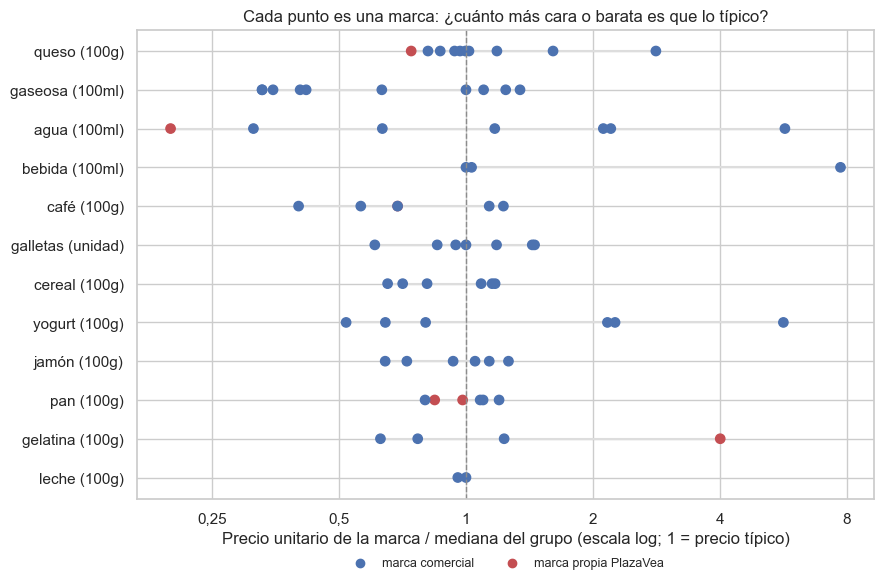

In [30]:
top = economica.head(12)["grupo_comparable"]
por_marca = (
    comparables[comparables["grupo_comparable"].isin(top)]
    .groupby(["grupo_comparable", "marca"])
    .agg(precio_relativo=("precio_relativo", "median"), es_marca_propia=("es_marca_propia", "max"))
    .reset_index()
)
etiqueta = {g: g.split(" | ")[1] + " (" + g.split(" | ")[2] + ")" for g in top}

fig, ax = plt.subplots(figsize=(9, 6))
for i, grupo in enumerate(top):
    sub = por_marca[por_marca["grupo_comparable"] == grupo]
    ax.plot([sub["precio_relativo"].min(), sub["precio_relativo"].max()], [i, i], color="#DDDDDD", zorder=1)
    ax.scatter(sub["precio_relativo"], [i] * len(sub),
               c=np.where(sub["es_marca_propia"], ROJO, AZUL), s=45, zorder=2)
ax.axvline(1, color=GRIS, ls="--", lw=1)
ax.set_xscale("log")
ax.set_xticks(TICKS_RELATIVO)
ax.set_xticklabels([f"{t:g}".replace(".", ",") for t in TICKS_RELATIVO])
ax.minorticks_off()
ax.set_yticks(range(len(top)))
ax.set_yticklabels([etiqueta[g] for g in top])
ax.invert_yaxis()
ax.set_xlabel("Precio unitario de la marca / mediana del grupo (escala log; 1 = precio típico)")
ax.set_title("Cada punto es una marca: ¿cuánto más cara o barata es que lo típico?")
ax.scatter([], [], c=AZUL, label="marca comercial")
ax.scatter([], [], c=ROJO, label="marca propia PlazaVea")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2, fontsize=9, frameon=False)
plt.tight_layout()
plt.savefig(FIGURAS / "f4_dispersion_marcas.png", dpi=120, bbox_inches="tight")
plt.show()

**Interpretación.** En casi todos los grupos hay una diferencia grande entre la marca más
barata y la más cara: en la mitad de los grupos la más cara cuesta 1,8 veces o más por 100 g /
100 ml / unidad que la más barata. Elegir la marca más económica ahorra, en la mediana de los 50
grupos, un 20,4 % frente al precio típico del grupo. Los extremos están en agua (la marca más
cara cuesta 28,7 veces la más barata por 100 ml, aunque aquí la brecha está inflada: es agua
mineral en pack de botellas de 500 ml frente a agua de mesa en bidón de 7 L) y en yogurt (10,9 veces). En gaseosas, la más barata (GUARANÁ) cuesta 67,2 % menos por
100 ml que la mediana del grupo; en café, SELLO ROJO cuesta 59,9 % menos que el café típico.

**Limitación.** La marca más barata no siempre es un sustituto exacto (calidad, sabor o tamaño
del envase cambian); el ranking dice dónde está el precio, no si el producto es equivalente.

## 3. ¿La marca propia de PlazaVea es la alternativa más barata?

El 17,6 % del catálogo es de marca propia (preprocesamiento). Para ver si es más barata sin
mezclar productos distintos, se compara la mediana del `precio_relativo` de la marca propia y de
las marcas comerciales **dentro de cada grupo** donde existen las dos.

grupos con marca propia y comercial a la vez: 26
grupos donde la marca propia es más barata:   23 (88.5 %)
mediana del precio relativo, marca propia:    0.888
mediana del precio relativo, comercial:       1.079


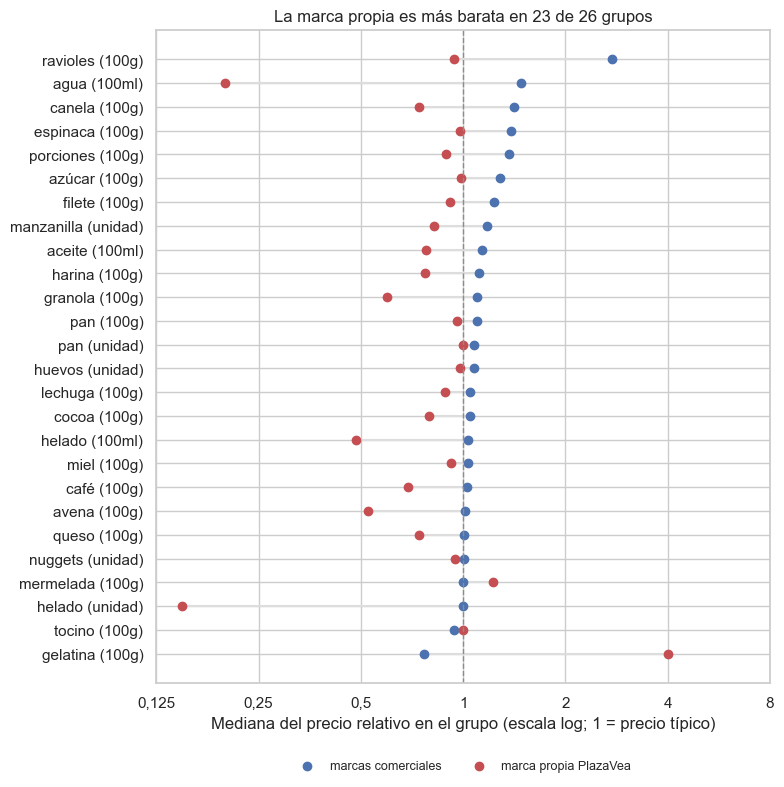

In [31]:
propia = comparar_marca_propia(comparables).sort_values("comercial")
n_barata = int(propia["propia_mas_barata"].sum())
print(f"grupos con marca propia y comercial a la vez: {len(propia)}")
print(f"grupos donde la marca propia es más barata:   {n_barata} ({n_barata / len(propia) * 100:.1f} %)")
print(f"mediana del precio relativo, marca propia:    {propia['marca_propia'].median():.3f}")
print(f"mediana del precio relativo, comercial:       {propia['comercial'].median():.3f}")

fig, ax = plt.subplots(figsize=(8, 8))
y = range(len(propia))
ax.hlines(y, propia["marca_propia"], propia["comercial"], color="#DDDDDD", zorder=1)
ax.scatter(propia["comercial"], y, color=AZUL, label="marcas comerciales", zorder=2)
ax.scatter(propia["marca_propia"], y, color=ROJO, label="marca propia PlazaVea", zorder=2)
ax.axvline(1, color=GRIS, ls="--", lw=1)
ax.set_xscale("log")
ax.set_xticks(TICKS_RELATIVO)
ax.set_xticklabels([f"{t:g}".replace(".", ",") for t in TICKS_RELATIVO])
ax.minorticks_off()
ax.set_yticks(list(y))
ax.set_yticklabels([g.split(" | ")[1] + " (" + g.split(" | ")[2] + ")" for g in propia.index])
ax.set_xlabel("Mediana del precio relativo en el grupo (escala log; 1 = precio típico)")
ax.set_title(f"La marca propia es más barata en {n_barata} de {len(propia)} grupos")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2, fontsize=9, frameon=False)
plt.tight_layout()
plt.savefig(FIGURAS / "f4_marca_propia_vs_comercial.png", dpi=120, bbox_inches="tight")
plt.show()

**Interpretación.** En 23 de los 26 grupos donde conviven ambas (88,5 %), la marca propia
de PlazaVea es más barata por unidad que la mediana de las marcas comerciales. Su producto típico
cuesta 0,89 veces el precio típico del grupo, frente a 1,08 de las comerciales: unos 19 puntos
de diferencia. Además, en 15 de los 50 grupos comparables la marca más barata de todas es una
marca propia (sobre todo BELL'S). Las 3 excepciones son gelatina, mermelada y tocino; en
gelatina la marca propia sale más cara porque BELL'S solo vende gelatina light en sobres de
19 g, que por gramo cuesta más que las bolsas regulares de 130 g (limitación de la sección 1).

**Recomendación.** Para un consumidor que busca ahorrar, la marca propia es la primera opción a
revisar en abarrotes, desayunos, helados y bebidas; en el resto conviene revisar la tabla
`docs/marca_mas_economica.csv`.

**Limitación.** 26 grupos es una muestra chica y no aleatoria; la diferencia es consistente
(23 de 26) pero no se puede generalizar a todo el catálogo de PlazaVea.

## 4. ¿Dónde se concentra el precio exclusivo con tarjeta Oh!?

`tiene_precio_oh` indica si el producto muestra un precio exclusivo para la tarjeta Oh!. El
scraping solo guardó si ese precio existe, no su monto, así que se analiza **dónde** aparece y no
cuánto se ahorra con él. Se miran dos cosas: la tasa (qué % de la categoría tiene precio Oh!) y
la participación (qué parte de todos los precios Oh! del catálogo cae en esa categoría).

In [32]:
oh_categoria = concentracion_oh(df, "categoria")
oh_macro = concentracion_oh(df, "macro_grupo")
print(f"productos con precio Oh!: {int(df['tiene_precio_oh'].sum())} de {len(df)} ({df['tiene_precio_oh'].mean() * 100:.1f} %)")
print()
print(oh_categoria)
print()
print(oh_macro)

top3 = oh_categoria.sort_values("participacion_pct", ascending=False).head(3)
print(f"\nlas 3 categorías con más precios Oh! concentran el {top3['participacion_pct'].sum():.1f} % del total")

productos con precio Oh!: 96 de 1491 (6.4 %)

                     n  con_oh  tasa_oh_pct  participacion_pct
categoria                                                     
Abarrotes          150      23         15.3               24.0
Carnes y Pescados  150      17         11.3               17.7
Cuidado Personal   150      15         10.0               15.6
Desayunos          150      10          6.7               10.4
Quesos y Fiambres  149       8          5.4                8.3
Frutas y Verduras  150       8          5.3                8.3
Lácteos            150       6          4.0                6.2
Congelados         145       5          3.4                5.2
Bebidas            150       4          2.7                4.2
Panadería          147       0          0.0                0.0

                    n  con_oh  tasa_oh_pct  participacion_pct
macro_grupo                                                  
Cuidado Personal  150      15         10.0               15.6
Envasados  

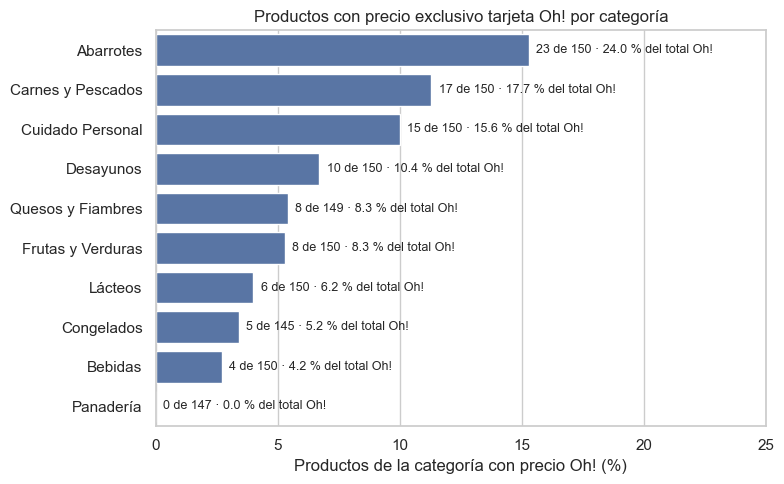

In [33]:
fig, ax = plt.subplots(figsize=(8, 5))
orden = oh_categoria.index
sns.barplot(x=oh_categoria["tasa_oh_pct"], y=orden, order=orden, ax=ax, color=AZUL)
for i, (cat, fila) in enumerate(oh_categoria.iterrows()):
    ax.text(fila["tasa_oh_pct"] + 0.3, i,
            f"{int(fila['con_oh'])} de {int(fila['n'])} · {fila['participacion_pct']:.1f} % del total Oh!",
            va="center", fontsize=9)
ax.set_title("Productos con precio exclusivo tarjeta Oh! por categoría")
ax.set_xlabel("Productos de la categoría con precio Oh! (%)")
ax.set_ylabel("")
ax.set_xlim(0, 25)
plt.tight_layout()
plt.savefig(FIGURAS / "f4_tasa_oh_categoria.png", dpi=120, bbox_inches="tight")
plt.show()

**Interpretación.** El precio Oh! es poco común: solo 96 de 1491 productos (6,4 %) lo
tienen. Se concentra en Abarrotes (15,3 % de la categoría, y el 24,0 % de todos los precios Oh!),
Carnes y Pescados (11,3 %) y Cuidado Personal (10,0 %): estas tres categorías juntan el 57,3 % de
los precios Oh! del catálogo. En el otro extremo, Bebidas (2,7 %) y Panadería (ningún producto)
casi no lo usan.

**Limitación.** Una sola fecha de extracción: las promociones con tarjeta cambian por campaña, así
que esto describe dónde estaba el precio Oh! ese día.

## 5. ¿El precio Oh! se suma a la oferta normal o la reemplaza?

Si el precio Oh! apareciera sobre todo en productos sin oferta, la tarjeta sería la única forma
de conseguir un descuento en ellos. Se cruza con `tiene_descuento`, `oferta_significativa`,
`segmento_precio` y `es_marca_propia`.

% de productos (filas = tiene_precio_oh):
                 tiene_descuento  oferta_significativa  es_marca_propia
tiene_precio_oh                                                        
sin precio Oh!              46.9                  20.9             17.5
con precio Oh!              66.7                  35.4             19.8

% con precio Oh! por segmento de precio:
segmento_precio
Económico    4.2
Medio        8.1
Premium      7.1
Name: tiene_precio_oh, dtype: float64


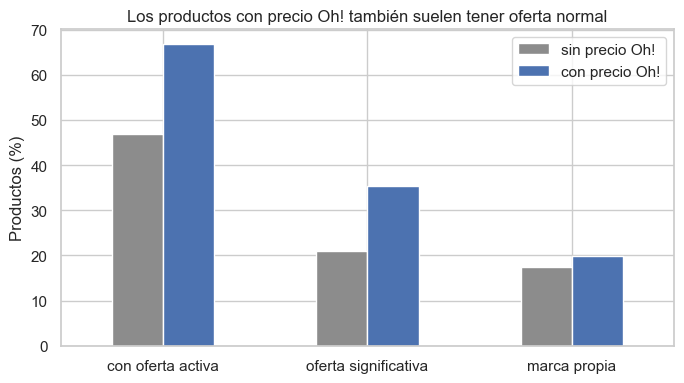

In [34]:
cruce = pd.DataFrame({
    col: df.groupby("tiene_precio_oh")[col].mean().mul(100).round(1)
    for col in ["tiene_descuento", "oferta_significativa", "es_marca_propia"]
}).rename(index={False: "sin precio Oh!", True: "con precio Oh!"})
print("% de productos (filas = tiene_precio_oh):")
print(cruce)

print("\n% con precio Oh! por segmento de precio:")
print(df.groupby("segmento_precio", observed=True)["tiene_precio_oh"].mean().mul(100).round(1))

fig, ax = plt.subplots(figsize=(7, 4))
cruce.T.plot(kind="bar", ax=ax, color=[GRIS, AZUL])
ax.set_title("Los productos con precio Oh! también suelen tener oferta normal")
ax.set_ylabel("Productos (%)")
ax.set_xticklabels(["con oferta activa", "oferta significativa", "marca propia"], rotation=0)
ax.legend(title="")
plt.tight_layout()
plt.savefig(FIGURAS / "f4_oh_vs_oferta.png", dpi=120, bbox_inches="tight")
plt.show()

**Interpretación.** El precio Oh! se suma a la oferta normal en lugar de reemplazarla: el
66,7 % de los productos con precio Oh! ya tiene una oferta activa, frente al 46,9 % de los que no
lo tienen, y la proporción de ofertas significativas es casi el doble (35,4 % frente a 20,9 %). Es
decir, la tarjeta suele dar un descuento adicional sobre productos que ya están en promoción. Por
segmento, el precio Oh! aparece menos en los productos Económicos (4,2 %) que en los Medios
(8,1 %) y Premium (7,1 %). La marca propia no se diferencia (19,8 % de los productos con precio
Oh! frente a 17,6 % del catálogo).

**Recomendación.** Para el consumidor con tarjeta Oh!, conviene revisar el precio con tarjeta
sobre todo en Abarrotes, Carnes y Pescados y Cuidado Personal, y en productos que ya están en
oferta: ahí es donde se acumulan los dos descuentos.

## 6. Verificación

In [35]:
figuras_p4 = ["f4_dispersion_marcas.png", "f4_marca_propia_vs_comercial.png",
              "f4_tasa_oh_categoria.png", "f4_oh_vs_oferta.png"]
for nombre in figuras_p4:
    ruta = FIGURAS / nombre
    print(("OK   " if ruta.exists() else "FALLA"), ruta)
print(("OK   " if (DOCS / "marca_mas_economica.csv").exists() else "FALLA"), DOCS / "marca_mas_economica.csv")

# la comparación no toca el dataset final: sigue con las mismas filas y columnas
assert df.shape == (1491, 23), df.shape
assert comparables["precio_relativo"].notna().all()

pd.DataFrame(bitacora).to_csv(DOCS / "bitacora_decisiones.csv", index=False, encoding="utf-8", lineterminator="\n")
print(f"bitácora actualizada: {len(bitacora)} decisiones")

OK    ..\docs\figures\f4_dispersion_marcas.png
OK    ..\docs\figures\f4_marca_propia_vs_comercial.png
OK    ..\docs\figures\f4_tasa_oh_categoria.png
OK    ..\docs\figures\f4_oh_vs_oferta.png
OK    ..\docs\marca_mas_economica.csv
bitácora actualizada: 11 decisiones


## 7. Conclusiones de esta parte

**Qué se encontró**
- **Objetivo 5.** Entre productos del mismo tipo, la marca importa mucho: en la mitad de los 50
  grupos comparables la marca más cara cuesta 1,8 veces o más que la más barata por unidad, y
  elegir la más barata ahorra un 20,4 % frente al precio típico (mediana).
- La marca propia de PlazaVea es más barata que las marcas comerciales en 23 de 26 grupos donde
  compiten, y es la opción más barata de todo el grupo en 15 de 50.
- **Objetivo 6.** El precio Oh! es poco frecuente (6,4 % del catálogo) y se concentra en
  Abarrotes, Carnes y Pescados y Cuidado Personal (57,3 % de todos los precios Oh!). Suele
  sumarse a una oferta que ya existe, no reemplazarla.

**Limitaciones**
- Solo el 57,7 % de los productos trae su contenido en el nombre; el resto no entra en la
  comparación por unidad.
- `tipo_producto` (primera palabra del nombre) junta a veces productos que no son sustitutos.
- No se guardó el monto del precio Oh!, así que no se puede medir cuánto se ahorra con la tarjeta.
- Una sola fecha y zona de entrega, sin muestreo aleatorio.

**Salidas:** `docs/marca_mas_economica.csv`, `docs/figures/f4_*.png` (contenido para las
diapositivas en `docs/diapositivas_p4.md`).